In [1]:
!pip install -q pymoo

HISTORICAL BASELINE (Manual)   -> F1: 0.1050 | F2: 56.47 MCM | F3: 78.8%
COMPROMISE OPTIMAL (Telemetry) -> F1: 0.1045 | F2: 25.69 MCM | F3: 80.7%
Peak Outflow during Max Storm  -> Manual Lag: 11.56 MCM/d vs. Telemetry: 9.09 MCM/d
Optimal Monthly Active Storage Targets (Jan-Dec, MCM):
[41.31 52.1  46.67 40.87 22.21 19.45 53.53 53.42 55.82 55.88 53.9  55.46]


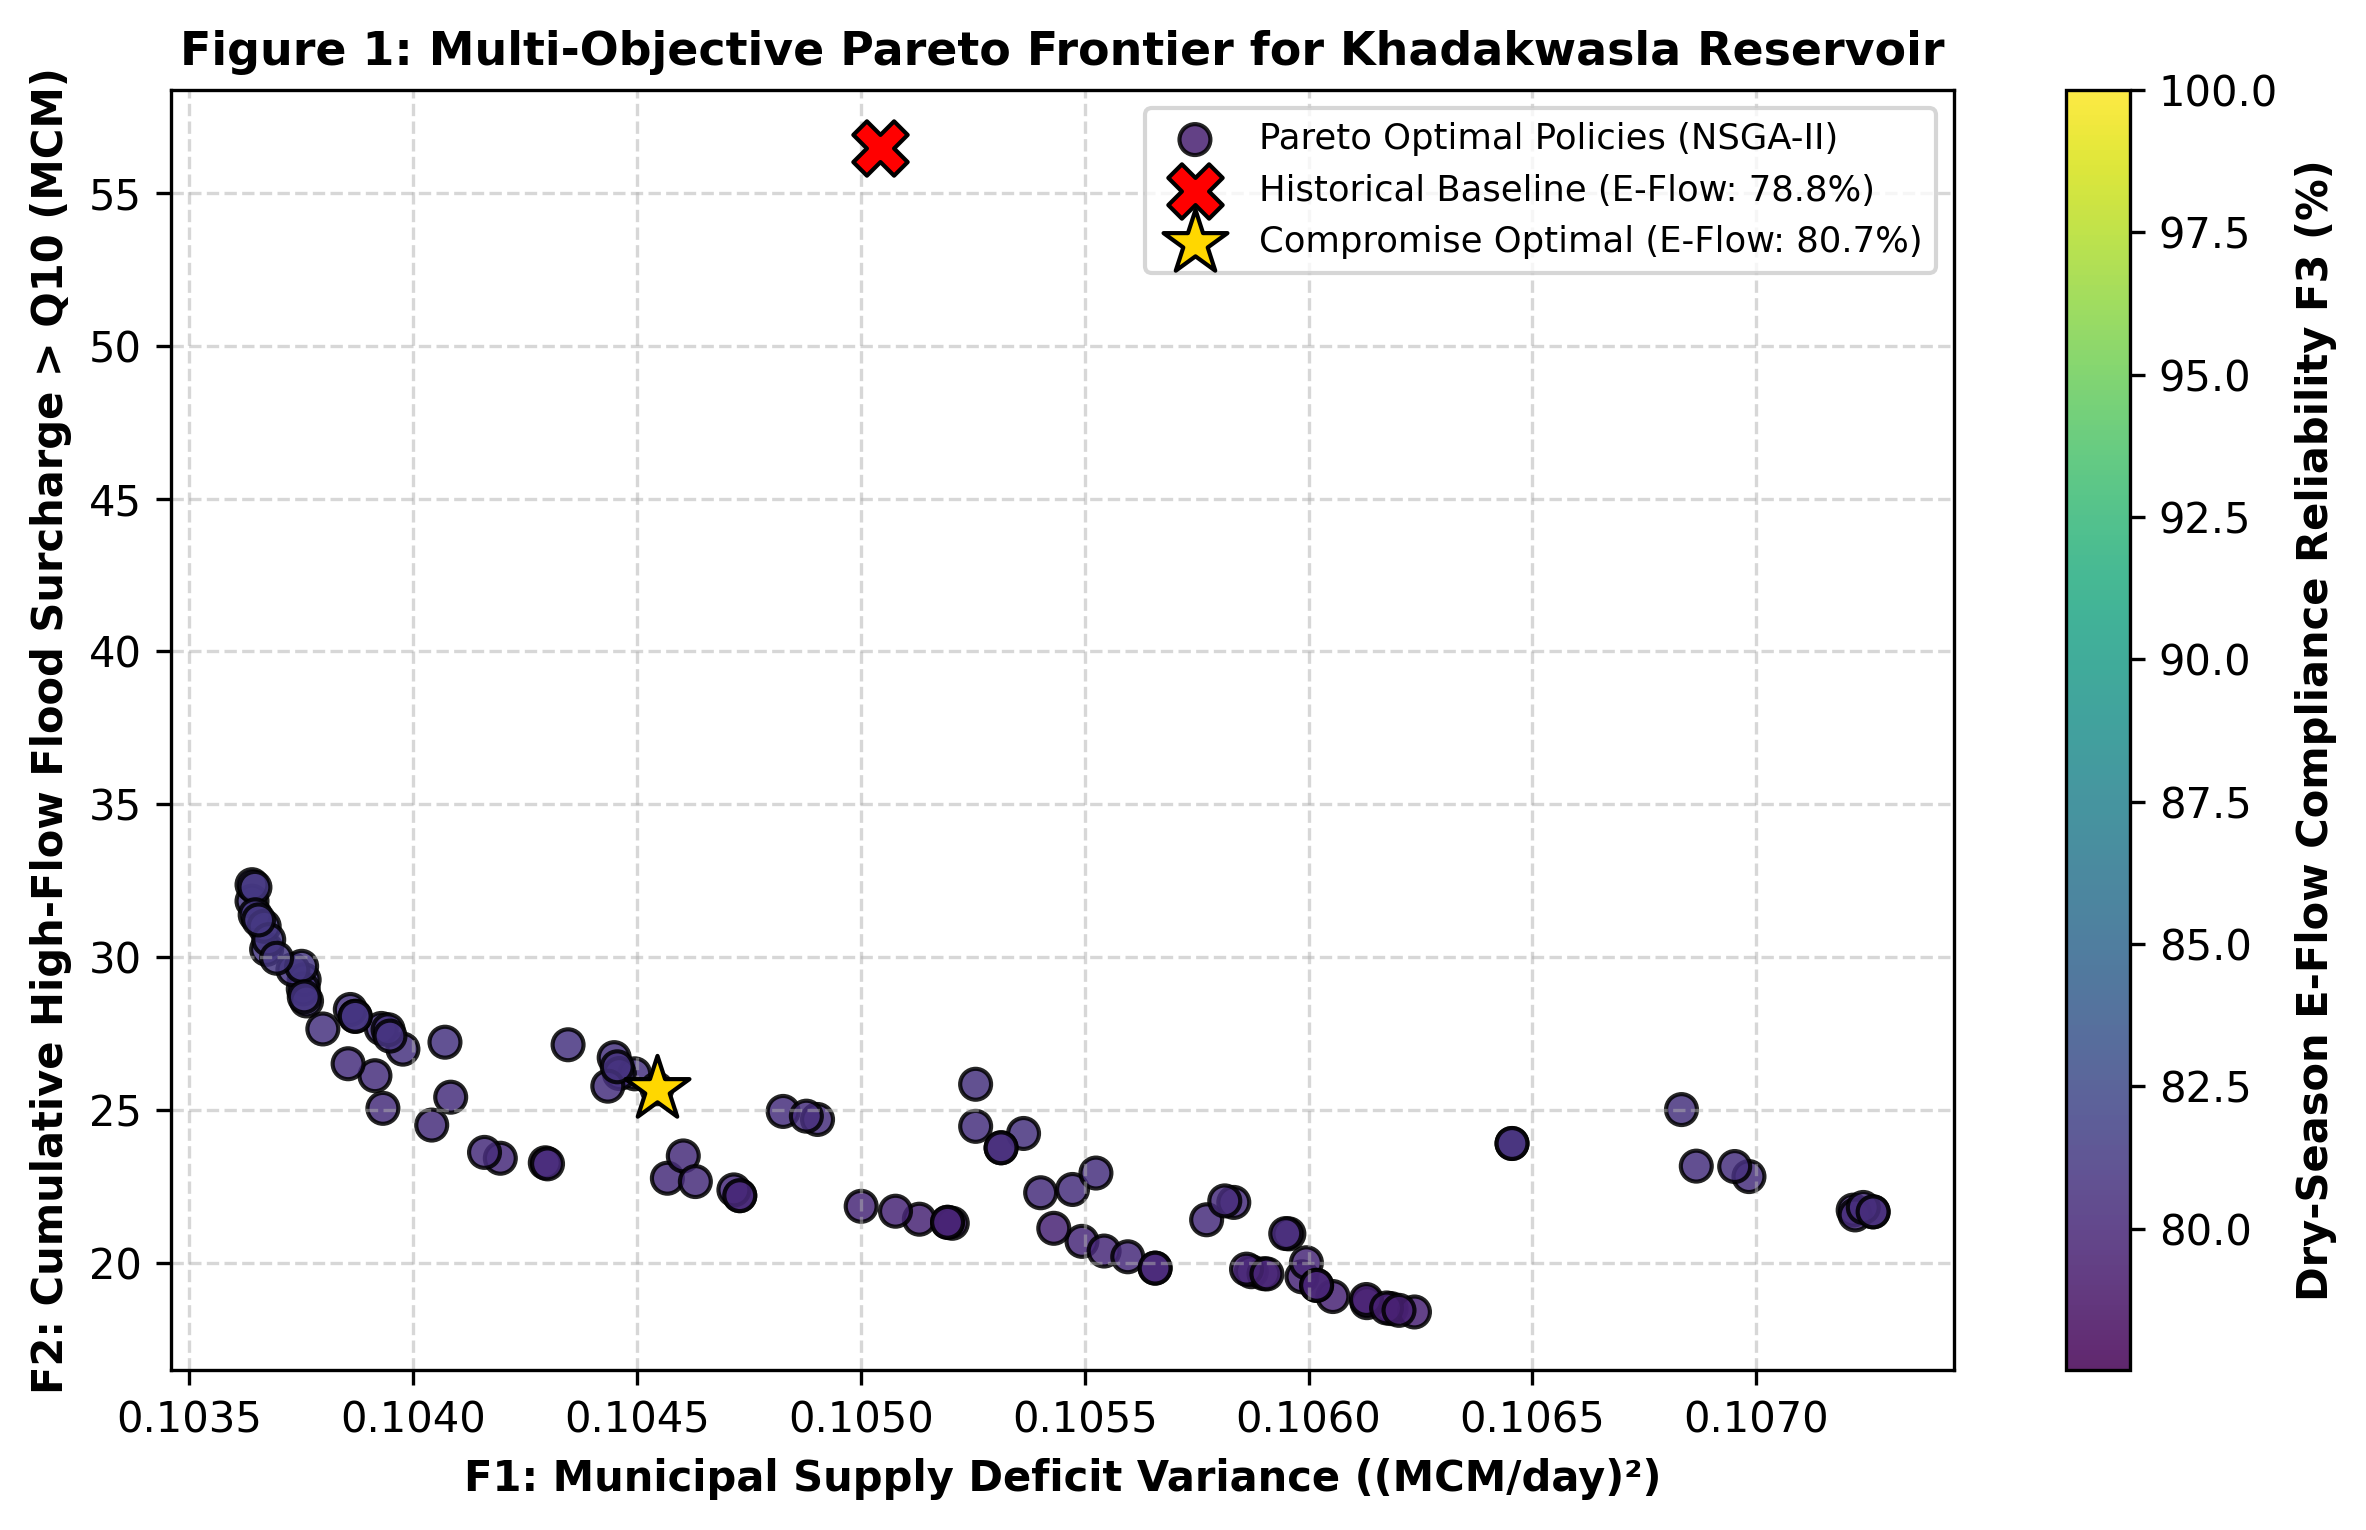

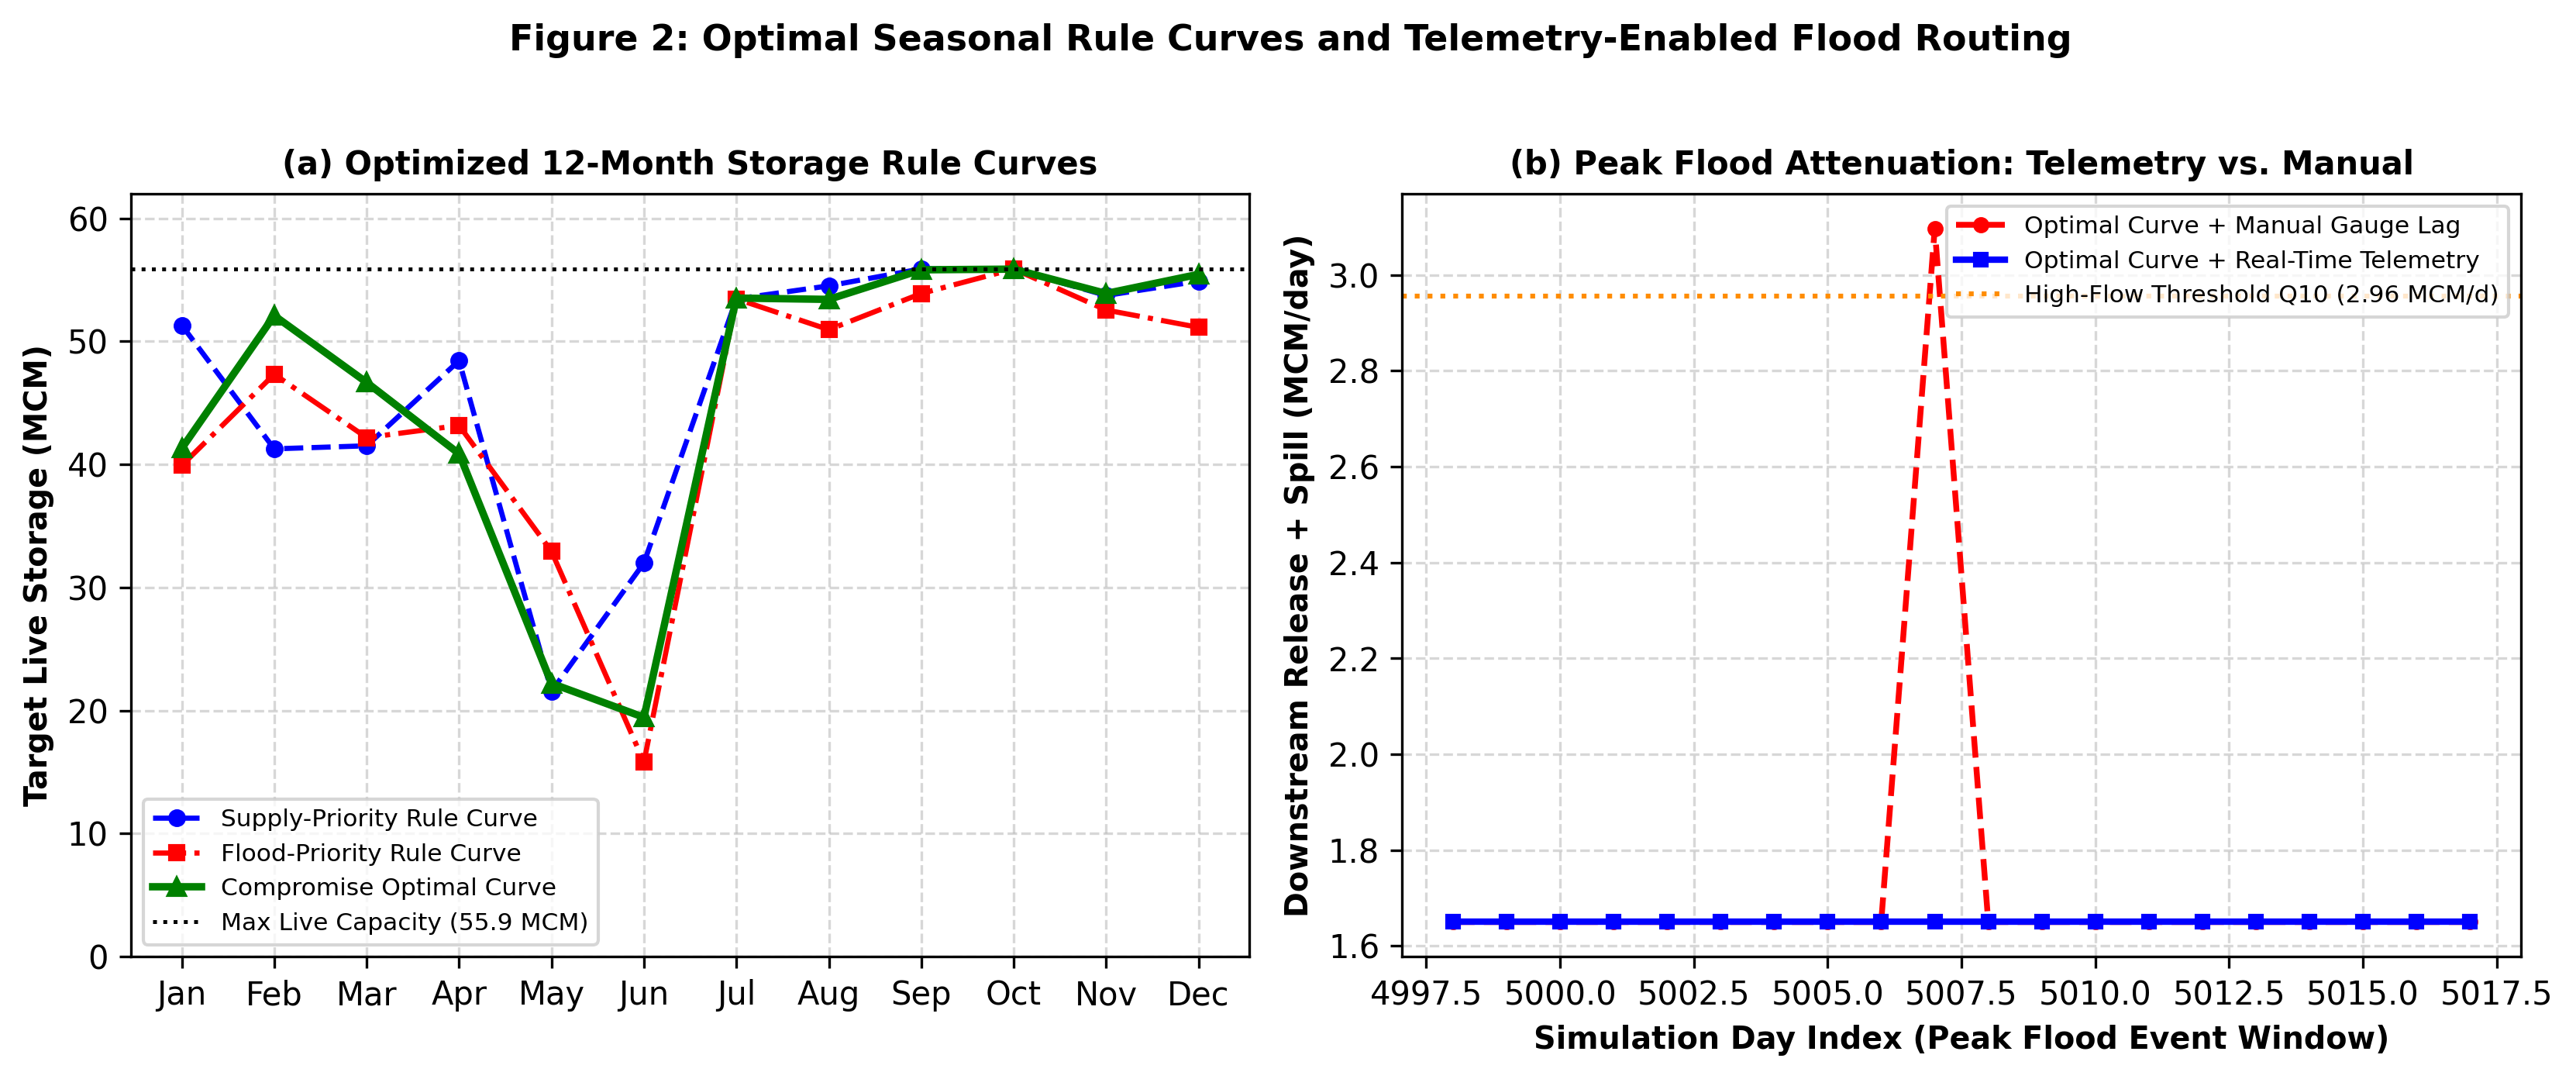

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
from google.colab import files


df = pd.read_csv('khadakwasla_cleaned.csv')
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month

inflows = df['Inflow_MCM'].values
months = df['Month'].values
T = len(inflows)

S_LIVE_MAX = 55.90      
D_MUNICIPAL = 1.65       
Q_SAFE = 85.50           
Q_10 = 2.955             
Q_90 = 0.295           


evap = np.where((months >= 6) & (months <= 9), 0.045,
       np.where((months >= 10) | (months <= 1), 0.068, 0.105))
is_dry = (months >= 10) | (months <= 5)


def simulate_reservoir(rule_curve, telemetry=True):
    S = df['Live_Storage_MCM'].iloc[0]
    releases = np.zeros(T)
    spills = np.zeros(T)
    storages = np.zeros(T)

    for t in range(T):
        m_idx = months[t] - 1
        S_target = rule_curve[m_idx]

  
        observed_inflow = inflows[t] if telemetry else (inflows[t-1] if t > 0 else inflows[0])
        W_est = S + observed_inflow - evap[t]

       
        req_release = D_MUNICIPAL + (Q_90 if is_dry[t] else 0.0)

        if W_est - req_release > S_target:
            
            excess = W_est - req_release - S_target
            R_target = req_release + 0.5 * excess
        else:
            R_target = req_release

        W_actual = S + inflows[t] - evap[t]
        R_actual = min(max(0.0, W_actual), R_target)

        rem_storage = W_actual - R_actual
        if rem_storage > S_LIVE_MAX:
            spill = rem_storage - S_LIVE_MAX
            S_next = S_LIVE_MAX
        else:
            spill = 0.0
            S_next = max(0.0, rem_storage)

        releases[t] = R_actual
        spills[t] = spill
        storages[t] = S_next
        S = S_next

  
    deficits = np.maximum(0.0, D_MUNICIPAL - releases)
    F1 = np.mean(deficits ** 2)


    total_outflow = releases + spills
    F2 = np.sum(np.maximum(0.0, total_outflow - Q_10))

    
    dry_releases = releases[is_dry]
    F3 = np.mean(dry_releases >= (D_MUNICIPAL + Q_90 - 1e-3)) * 100.0

    return F1, F2, F3, storages, total_outflow


baseline_curve = np.full(12, S_LIVE_MAX)
base_F1, base_F2, base_F3, base_S, base_Q = simulate_reservoir(baseline_curve, telemetry=False)


class KhadakwaslaProblem(ElementwiseProblem):
    def __init__(self):
        super().__init__(n_var=12, n_obj=3, xl=5.0, xu=S_LIVE_MAX)

    def _evaluate(self, x, out, *args, **kwargs):
        F1, F2, F3, _, _ = simulate_reservoir(x, telemetry=True)
        out["F"] = [F1, F2, -F3]

problem = KhadakwaslaProblem()
algorithm = NSGA2(pop_size=100)
res = minimize(problem, algorithm, ('n_gen', 200), seed=42, verbose=False)

pareto_F = res.F
pareto_X = res.X
pareto_F[:, 2] = -pareto_F[:, 2]

norm_F = (pareto_F - pareto_F.min(axis=0)) / (np.ptp(pareto_F, axis=0) + 1e-9)
norm_F[:, 2] = 1.0 - norm_F[:, 2]
comp_idx = np.argmin(np.linalg.norm(norm_F, axis=1))
comp_curve = pareto_X[comp_idx]
comp_F1, comp_F2, comp_F3, comp_S, comp_Q_tel = simulate_reservoir(comp_curve, telemetry=True)
_, _, _, _, comp_Q_man = simulate_reservoir(comp_curve, telemetry=False)


print("="*65)
print(f"HISTORICAL BASELINE (Manual)   -> F1: {base_F1:.4f} | F2: {base_F2:.2f} MCM | F3: {base_F3:.1f}%")
print(f"COMPROMISE OPTIMAL (Telemetry) -> F1: {comp_F1:.4f} | F2: {comp_F2:.2f} MCM | F3: {comp_F3:.1f}%")
print(f"Peak Outflow during Max Storm  -> Manual Lag: {comp_Q_man.max():.2f} MCM/d vs. Telemetry: {comp_Q_tel.max():.2f} MCM/d")
print("Optimal Monthly Active Storage Targets (Jan-Dec, MCM):")
print(np.round(comp_curve, 2))
print("="*65)


plt.figure(figsize=(8.2, 5.2), dpi=300)
sc = plt.scatter(pareto_F[:, 0], pareto_F[:, 1], c=pareto_F[:, 2], cmap='viridis',
                 vmin=max(0, pareto_F[:, 2].min() - 2), vmax=100.0,
                 s=55, edgecolor='k', alpha=0.85, label='Pareto Optimal Policies (NSGA-II)')
plt.scatter(base_F1, base_F2, color='red', marker='X', s=170, edgecolor='black', zorder=5,
            label=f'Historical Baseline (E-Flow: {base_F3:.1f}%)')
plt.scatter(comp_F1, comp_F2, color='gold', marker='*', s=260, edgecolor='black', zorder=6,
            label=f'Compromise Optimal (E-Flow: {comp_F3:.1f}%)')
cbar = plt.colorbar(sc)
cbar.set_label('Dry-Season E-Flow Compliance Reliability F3 (%)', fontsize=10, fontweight='bold')
plt.xlabel('F1: Municipal Supply Deficit Variance ((MCM/day)²)', fontsize=10, fontweight='bold')
plt.ylabel('F2: Cumulative High-Flow Flood Surcharge > Q10 (MCM)', fontsize=10, fontweight='bold')
plt.title('Figure 1: Multi-Objective Pareto Frontier for Khadakwasla Reservoir', fontsize=11, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='best', fontsize=8.5, frameon=True)
plt.tight_layout()
plt.savefig('Figure_1.png', dpi=300)
plt.show()


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 4.5), dpi=300)
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

flood_idx = np.argmin(pareto_F[:, 1])
supply_idx = np.argmin(pareto_F[:, 0])
ax1.plot(month_labels, pareto_X[supply_idx], 'b--o', lw=1.6, markersize=4.5, label='Supply-Priority Rule Curve')
ax1.plot(month_labels, pareto_X[flood_idx], 'r-.s', lw=1.6, markersize=4.5, label='Flood-Priority Rule Curve')
ax1.plot(month_labels, comp_curve, 'g-^', lw=2.3, markersize=5.5, label='Compromise Optimal Curve')
ax1.axhline(S_LIVE_MAX, color='k', ls=':', lw=1.2, label='Max Live Capacity (55.9 MCM)')
ax1.set_ylabel('Target Live Storage (MCM)', fontsize=9.5, fontweight='bold')
ax1.set_title('(a) Optimized 12-Month Storage Rule Curves', fontsize=10, fontweight='bold')
ax1.set_ylim(0, 62)
ax1.grid(True, ls='--', alpha=0.5)
ax1.legend(fontsize=7.5, loc='lower left')

peak_day = np.argmax(inflows)
window = slice(max(0, peak_day - 8), min(T, peak_day + 12))
days_x = np.arange(window.start, window.stop)
ax2.plot(days_x, comp_Q_man[window], 'r--o', lw=1.8, markersize=4, label='Optimal Curve + Manual Gauge Lag')
ax2.plot(days_x, comp_Q_tel[window], 'b-s', lw=2.0, markersize=4, label='Optimal Curve + Real-Time Telemetry')
ax2.axhline(Q_10, color='darkorange', ls=':', lw=1.5, label='High-Flow Threshold Q10 (2.96 MCM/d)')
ax2.set_xlabel('Simulation Day Index (Peak Flood Event Window)', fontsize=9.5, fontweight='bold')
ax2.set_ylabel('Downstream Release + Spill (MCM/day)', fontsize=9.5, fontweight='bold')
ax2.set_title('(b) Peak Flood Attenuation: Telemetry vs. Manual', fontsize=10, fontweight='bold')
ax2.grid(True, ls='--', alpha=0.5)
ax2.legend(fontsize=7.5, loc='upper right')

plt.suptitle('Figure 2: Optimal Seasonal Rule Curves and Telemetry-Enabled Flood Routing', fontsize=11, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Figure_2.png', dpi=300, bbox_inches='tight')
plt.show()

files.download('Figure_1.png')
files.download('Figure_2.png')